<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="115" alt="VGI logo"></a>

# What does a round total hide?

Use **Scottie Scheffler’s 2026 Masters scorecard** to reconcile hole scores with round totals, then inspect where strokes relative to par accumulated. A hole-by-round chart keeps the sequence visible; a par-group comparison separates total contribution from average per hole. The final experiment narrows the analysis to rounds three and four.

The real golf worker runs through Haybarn/VGI in both modes. The default **recorded** mode serves two unchanged repository test fixtures through supported endpoint overrides. Their original capture timestamp is undocumented; the leaderboard fixture contains only **eight players**, while this player’s regulation scorecard has all 72 holes. We analyze one player, not the whole field. **Live** mode requests the same historical event from ESPN and never falls back to the fixtures. The README records fixture hashes, provenance and source limitations.

## Choose the round window

`MIN_ROUND` is an integer from 1 through 4; include that round through round 4, with both endpoints inclusive. The default includes all four rounds. `DATA_MODE` is `"recorded"` or `"live"`. The event ID **401811941**, player ID **9478**, and PGA tour are fixed to this example’s coverage. Restart and run all after editing.

In [1]:
DATA_MODE = "recorded"
MIN_ROUND = 1  # Include rounds MIN_ROUND through 4; experiment: 3.

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

from notebook_support import finish, prose, theme
from recorded_api import configure

if type(MIN_ROUND) is not int or not 1 <= MIN_ROUND <= 4:
    raise ValueError("MIN_ROUND must be an integer from 1 through 4.")
replay = configure(DATA_MODE)
run_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-golf/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-golf/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-golf/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-golf/notebooks/pyproject.toml.

## Attach the published worker and retain the three results

The literal Git release command runs in an isolated uv environment. Leaderboard, course setup and scorecard calls are materialized before DataFrame captures. SQL filters the selected player from the returned leaderboard. The local replay server permits only this event and player; unsupported routes fail explicitly. Live setup clears all inherited endpoint overrides.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'golf' AS golf (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-golf@v0.2.0 vgi-golf');
CREATE TABLE leaderboard AS SELECT * FROM golf.main.leaderboard(event_id := 401811941);
CREATE TABLE player AS SELECT * FROM leaderboard WHERE player_id = 9478;
CREATE TABLE course AS SELECT * FROM golf.main.course_holes(401811941);
CREATE TABLE scorecard AS SELECT * FROM golf.main.player_scorecard(401811941, 9478);

8 rows affected.

1 rows affected.

18 rows affected.

72 rows affected.

,Count


In [4]:
%%sql event <<
SELECT event_name, season, player_name, event_completed, status, position,
       score_to_par, total_strokes, round_1, round_2, round_3, round_4,
       (SELECT count(*) FROM leaderboard) AS returned_leaderboard_rows,
       (SELECT count(*) FROM scorecard) AS returned_scorecard_rows,
       (SELECT count(*) FROM course) AS returned_course_holes
FROM player;

In [5]:
display(event)
assert len(event) == 1, "The selected player is absent or duplicated; inspect source availability."
e = event.iloc[0]
source = (
    "recorded repository fixtures; original capture time undocumented"
    if DATA_MODE == "recorded"
    else "live ESPN responses"
)
prose(
    f"Mode: **{DATA_MODE}** ({source}). Run started at **{run_utc}**; this clock is not a fixture capture time. "
    f"The returned data identifies **{e.player_name}**, **{e.event_name} {e.season}**, "
    f"with **{int(e.returned_scorecard_rows)} hole records**. "
    "The leaderboard supplies a cross-check for this player; its row count is not used "
    "as a tournament-field denominator."
)

,event_name,season,player_name,event_completed,status,position,score_to_par,total_strokes,round_1,round_2,round_3,round_4,returned_leaderboard_rows,returned_scorecard_rows,returned_course_holes
0,Masters Tournament,2026,Scottie Scheffler,True,Finish,2,-11,277,70,74,65,68,8,72,18


Mode: **recorded** (recorded repository fixtures; original capture time undocumented). Run started at **2026-11-14T06:55:08+00:00**; this clock is not a fixture capture time. The returned data identifies **Scottie Scheffler**, **Masters Tournament 2026**, with **72 hole records**. The leaderboard supplies a cross-check for this player; its row count is not used as a tournament-field denominator.

## Reconcile the complete scorecard before narrowing it

Join course setup on **event ID, course ID and hole number**; hole number alone is not a safe key for multi-course events. Keep the scorecard’s own par and compare it with the setup. A missing join, missing score or duplicate key stops the analysis. The complete four-round totals must agree with both the repeated scorecard round total and the player’s leaderboard totals before we apply the chosen round window.

In [6]:
%%sql
CREATE TABLE joined AS
SELECT s.*, c.course_name, c.par AS setup_par, c.yards
FROM scorecard s LEFT JOIN course c USING (tour, event_id, course_id, hole);
CREATE TABLE expected_rounds AS
SELECT 1 AS round, round_1 AS leaderboard_strokes FROM player
UNION ALL SELECT 2, round_2 FROM player
UNION ALL SELECT 3, round_3 FROM player
UNION ALL SELECT 4, round_4 FROM player;
CREATE TABLE round_totals AS
SELECT s.round, count(*) AS holes, sum(strokes) AS strokes,
       sum(par) AS total_par, sum(score_to_par) AS score_to_par,
       min(round_strokes) AS scorecard_round_strokes,
       max(round_strokes) AS maximum_round_strokes,
       e.leaderboard_strokes
FROM scorecard s JOIN expected_rounds e USING (round)
GROUP BY s.round, e.leaderboard_strokes;

72 rows affected.

4 rows affected.

4 rows affected.

,Count


In [7]:
%%sql rounds <<
SELECT * FROM round_totals ORDER BY round;

In [8]:
display(rounds)

,round,holes,strokes,total_par,score_to_par,scorecard_round_strokes,maximum_round_strokes,leaderboard_strokes
0,1,18,70.0,72.0,-2.0,70,70,70
1,2,18,74.0,72.0,2.0,74,74,74
2,3,18,65.0,72.0,-7.0,65,65,65
3,4,18,68.0,72.0,-4.0,68,68,68


In [9]:
%%sql checks <<
SELECT 'completed individual four-round event' AS check_name,
       count(*) = 1 AND bool_and(event_completed AND entry_type = 'athlete' AND rounds_played = 4) AS passed FROM player
UNION ALL SELECT 'scorecard identity unique', count(*) = count(DISTINCT (event_id,player_id,round,course_id,hole))
       AND bool_and(event_id = 401811941 AND player_id = 9478) FROM scorecard
UNION ALL SELECT 'course join has one matching setup per hole',
       count(*) = (SELECT count(*) FROM scorecard) AND count(setup_par) = count(*) FROM joined
UNION ALL SELECT 'scores and pars complete and consistent',
       count(strokes) = count(*) AND count(par) = count(*)
       AND bool_and(strokes > 0 AND par > 0 AND par = setup_par AND strokes - par = score_to_par) FROM joined
UNION ALL SELECT 'all four complete regulation rounds reconcile',
       count(*) = 4 AND bool_and(holes = 18 AND strokes = scorecard_round_strokes
       AND strokes = maximum_round_strokes AND strokes = leaderboard_strokes) FROM round_totals
UNION ALL SELECT 'full stroke total agrees with leaderboard',
       (SELECT sum(strokes) FROM scorecard) = total_strokes FROM player
UNION ALL SELECT 'full to-par total agrees with leaderboard',
       (SELECT sum(score_to_par) FROM scorecard) = score_to_par FROM player;

In [10]:
display(checks)
assert checks.passed.fillna(False).all(), "Scorecard coverage or reconciliation failed."

,check_name,passed
0,completed individual four-round event,True
1,scorecard identity unique,True
2,course join has one matching setup per hole,True
3,scores and pars complete and consistent,True
4,all four complete regulation rounds reconcile,True
5,full stroke total agrees with leaderboard,True
6,full to-par total agrees with leaderboard,True


## Follow the selected rounds hole by hole

Negative values are strokes **under** par, positive values are strokes **over** par, and zero is a completed par—not missing data. The color scale is symmetric and shared across rounds. This is one golfer’s scoring pattern; it does not estimate the field’s difficulty on a hole or explain what caused a score.

In [11]:
%%sql selected <<
SELECT round, hole, course_id, course_name, par, yards, strokes, score_to_par
FROM joined WHERE round BETWEEN {{MIN_ROUND}} AND 4 ORDER BY round, hole;

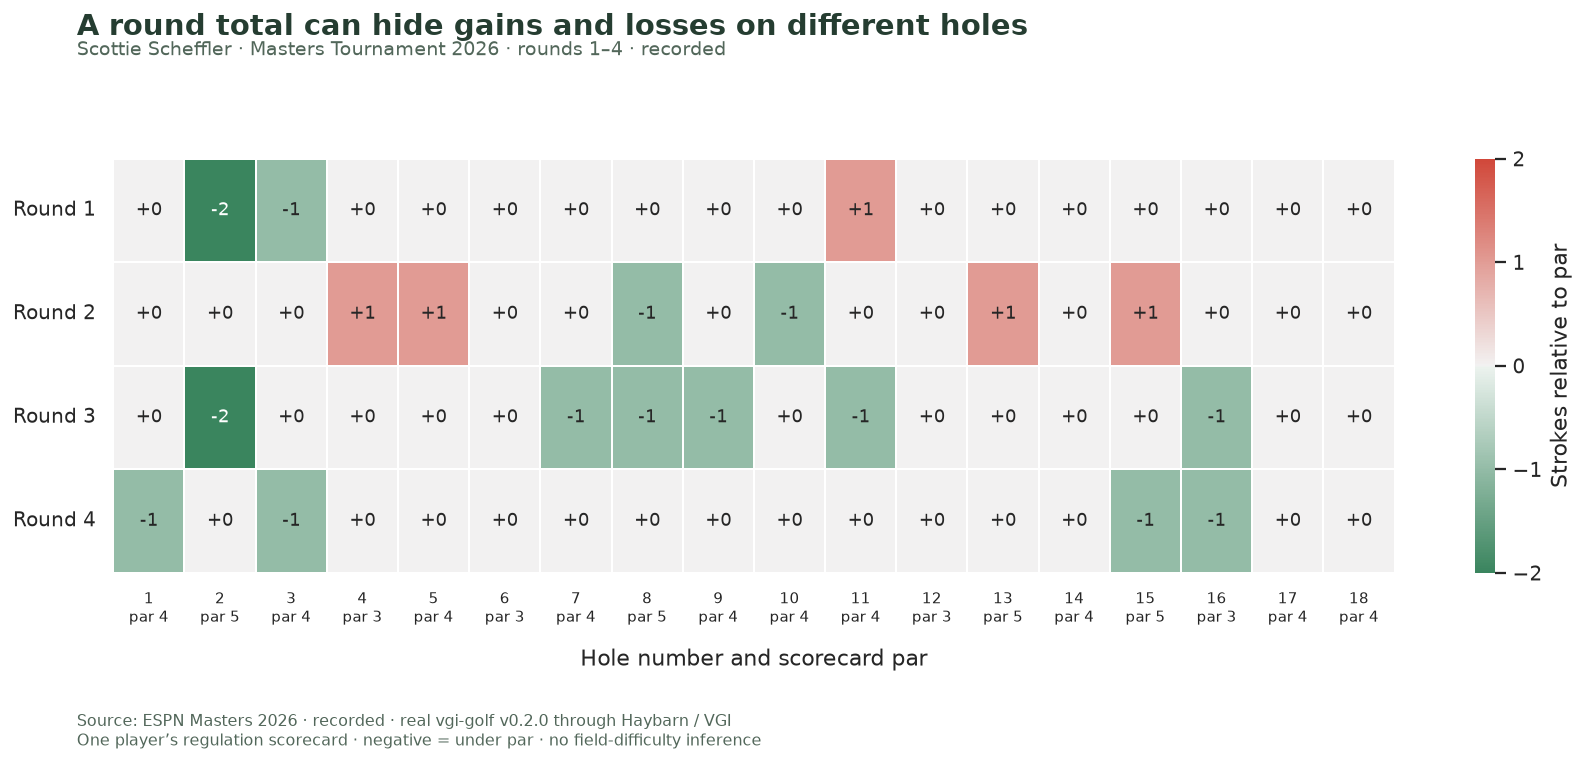

In [12]:
matrix = selected.pivot(index="round", columns="hole", values="score_to_par")
labels = selected.drop_duplicates("hole").set_index("hole").sort_index()
limit = max(2, int(selected.score_to_par.abs().max()))
fig, ax = plt.subplots(figsize=(14, 5.9))
sns.heatmap(
    matrix,
    ax=ax,
    annot=True,
    fmt="+d",
    cmap=sns.diverging_palette(145, 15, as_cmap=True),
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=1.0,
    linecolor="white",
    cbar_kws={"label": "Strokes relative to par", "ticks": range(-limit, limit + 1)},
    annot_kws={"fontsize": 10},
)
ax.set_xticklabels([f"{hole}\npar {int(labels.loc[hole, 'par'])}" for hole in matrix.columns], rotation=0, fontsize=8.5)
ax.set_yticklabels([f"Round {int(r)}" for r in matrix.index], rotation=0)
ax.set_xlabel("Hole number and scorecard par", labelpad=12)
ax.set_ylabel("")
fig.subplots_adjust(left=0.09, right=0.97, bottom=0.25, top=0.79)
finish(
    fig,
    "A round total can hide gains and losses on different holes",
    f"{e.player_name} · {e.event_name} {e.season} · rounds {MIN_ROUND}–4 · {DATA_MODE}",
    f"holes-{DATA_MODE}-{MIN_ROUND}.png",
    DATA_MODE,
)

In [13]:
total_strokes = int(selected.strokes.sum())
net = int(selected.score_to_par.sum())
under = int((selected.score_to_par < 0).sum())
over = int((selected.score_to_par > 0).sum())
prose(
    f"The selected **{len(selected)} holes** total **{total_strokes} strokes** and **{net:+d} relative to par**. "
    f"There are **{under} under-par holes**, **{over} over-par holes**, and "
    f"**{len(selected) - under - over} pars**. "
    "Net scoring hides the number and size of offsetting gains and losses. Next we group by par value "
    "and keep the number of played holes visible."
)

The selected **72 holes** total **277 strokes** and **-11 relative to par**. There are **14 under-par holes**, **5 over-par holes**, and **53 pars**. Net scoring hides the number and size of offsetting gains and losses. Next we group by par value and keep the number of played holes visible.

## Separate total contribution from average per played hole

Par-4 holes occur more often than par-3 or par-5 holes in this setup, so their totals have different exposure. The left panel adds strokes relative to par; the right divides each group’s total by its **number of played holes**. These panels deliberately have different units and separate axes. A zero average means net even par; an absent group would be unavailable and is not invented as zero.

In [14]:
%%sql by_par <<
SELECT par, count(*) AS played_holes, sum(score_to_par) AS total_to_par,
       avg(score_to_par) AS mean_to_par_per_hole,
       count(*) FILTER (WHERE score_to_par < 0) AS under_par_holes,
       count(*) FILTER (WHERE score_to_par = 0) AS pars,
       count(*) FILTER (WHERE score_to_par > 0) AS over_par_holes
FROM joined WHERE round BETWEEN {{MIN_ROUND}} AND 4 GROUP BY par ORDER BY par;

,par,played_holes,total_to_par,mean_to_par_per_hole,under_par_holes,pars,over_par_holes
0,3,16,-1.0,-0.0625,2,13,1
1,4,40,-5.0,-0.1250,7,31,2
2,5,16,-5.0,-0.3125,5,9,2


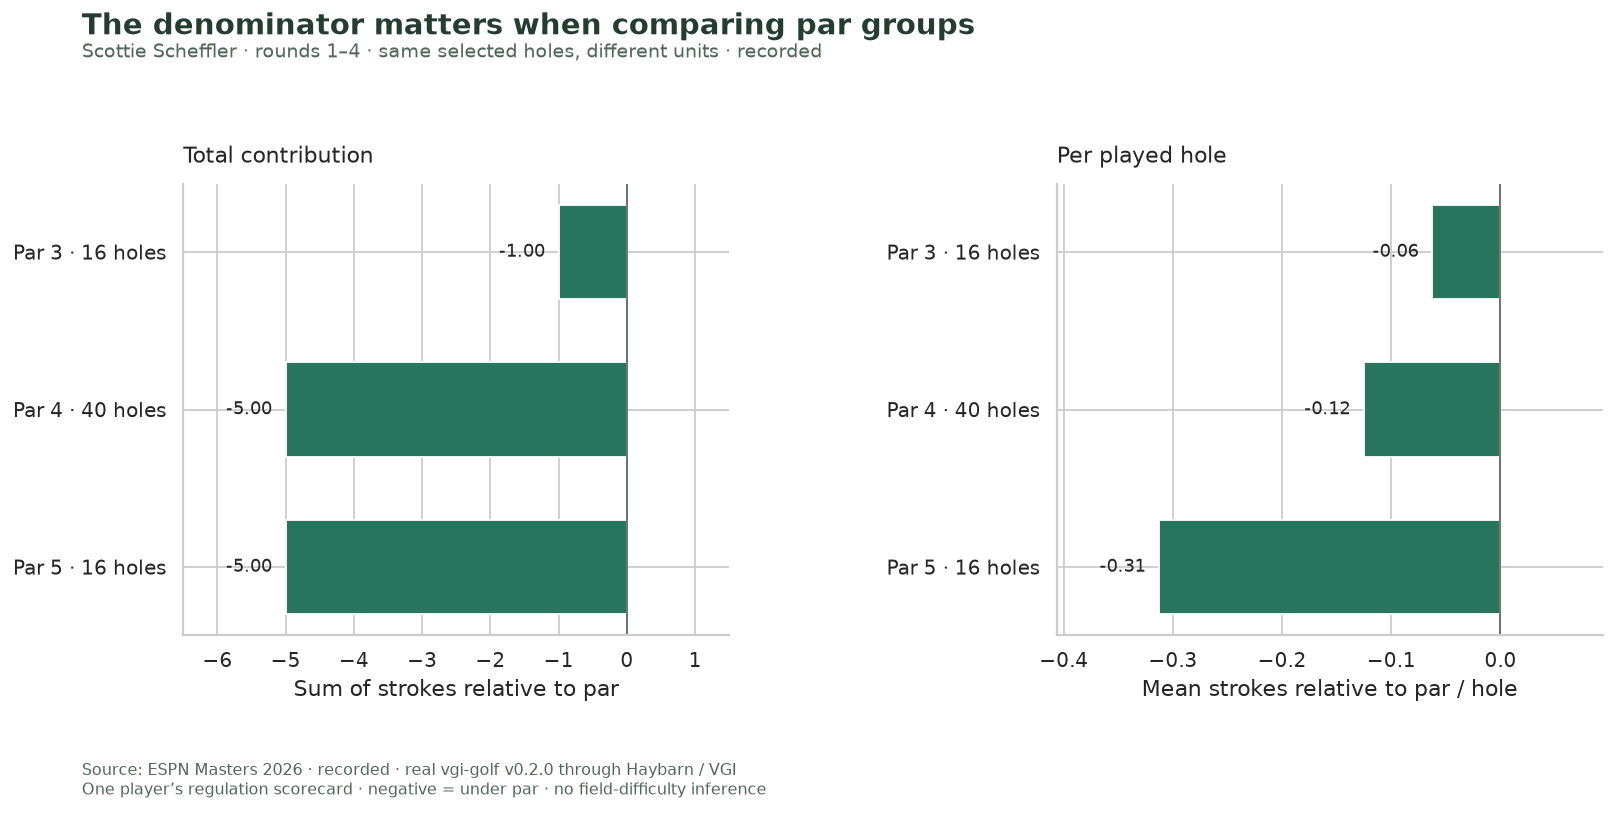

In [15]:
display(by_par)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
y = np.arange(len(by_par))
for ax, column, title, unit in [
    (axes[0], "total_to_par", "Total contribution", "Sum of strokes relative to par"),
    (axes[1], "mean_to_par_per_hole", "Per played hole", "Mean strokes relative to par / hole"),
]:
    values = by_par[column].to_numpy()
    colors = ["#27765d" if v < 0 else "#b05b60" if v > 0 else "#7d8580" for v in values]
    ax.barh(y, values, color=colors, height=0.6)
    ax.axvline(0, color="#626b65", linewidth=1)
    span = max(abs(values).max(), 0.1)
    for i, value in enumerate(values):
        ax.text(
            value + (span * 0.04 if value >= 0 else -span * 0.04),
            i,
            f"{value:+.2f}",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=10,
        )
    ax.set_xlim(min(0, values.min()) - span * 0.3, max(0, values.max()) + span * 0.3)
    ax.set_yticks(y, [f"Par {row.par} · {row.played_holes} holes" for row in by_par.itertuples()])
    ax.invert_yaxis()
    ax.set_title(title, loc="left", fontsize=12, pad=12)
    ax.set_xlabel(unit)
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.22, top=0.77, wspace=0.6)
finish(
    fig,
    "The denominator matters when comparing par groups",
    f"{e.player_name} · rounds {MIN_ROUND}–4 · same selected holes, different units · {DATA_MODE}",
    f"par-groups-{DATA_MODE}-{MIN_ROUND}.png",
    DATA_MODE,
)

In [16]:
%%sql group_checks <<
SELECT 'par groups retain every selected hole' AS check_name,
       count(*) = (SELECT sum(played_holes) FROM (
           SELECT count(*) played_holes FROM joined WHERE round BETWEEN {{MIN_ROUND}} AND 4 GROUP BY par)) AS passed
FROM joined WHERE round BETWEEN {{MIN_ROUND}} AND 4
UNION ALL SELECT 'signed group averages reconstruct totals',
       bool_and(abs(mean_to_par * n - total_to_par) < 1e-8)
FROM (SELECT count(*) n, avg(score_to_par) mean_to_par, sum(score_to_par) total_to_par
      FROM joined WHERE round BETWEEN {{MIN_ROUND}} AND 4 GROUP BY par);

In [17]:
display(group_checks)
assert group_checks.passed.fillna(False).all(), "Par-group accounting failed."
best = by_par.loc[by_par.mean_to_par_per_hole.idxmin()]
prose(
    f"In this selected window, the lowest mean is on **par-{int(best.par)} holes**: "
    f"**{best.mean_to_par_per_hole:+.2f} strokes per played hole**, across **{int(best.played_holes)} holes**. "
    f"All **{len(checks) + len(group_checks)} source and accounting checks** pass. "
    "This is a descriptive comparison for one player and window; it does not rank intrinsic hole difficulty "
    "or forecast another round."
)

,check_name,passed
0,par groups retain every selected hole,True
1,signed group averages reconstruct totals,True


In this selected window, the lowest mean is on **par-5 holes**: **-0.31 strokes per played hole**, across **16 holes**. All **9 source and accounting checks** pass. This is a descriptive comparison for one player and window; it does not rank intrinsic hole difficulty or forecast another round.

## Experiment: keep only the weekend rounds

Change **`MIN_ROUND = 1` to `3`**, restart and run all, and compare the heatmap and par-group averages. The complete-source reconciliation should still pass, while the analytical window shrinks from four rounds to two. Predict which par group will change most from its first two rounds, then inspect the returned averages; neither the total nor the average is required to move in a particular direction. Restore **1** for the default.

Keep `DATA_MODE = "recorded"` for an exact fixture comparison. Live mode retrieves the same historical event, but upstream corrections or unavailable endpoints can change results or stop execution. The README includes separate-output commands for both the experiment and live check.

In [18]:
connection.close()
if replay is not None:
    replay.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Source: ESPN via vgi-golf; fixture details in [README](README.md)